# 03 — CLTV KPI driver diagnostics
A dashboard-oriented synthetic case study: compare today against 1-, 7-, and 30-day baselines; decompose aggregate revenue per active viewer; use lagged correlations and Timestral historical ablations as **predictive diagnostics**, not causal effects.

**Definition used in this demo:** `CLTV proxy = daily revenue / daily active viewers`. This is **not** realized lifetime value or cohort-predicted LTV. Replace it with your business-approved CLTV definition before production use.

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn torch safetensors huggingface_hub git+https://github.com/mistralai/timestral.git@a534bdbd244d64f3d9d743f46c7bf6fc330ed4ff


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /Users/linghuang/miniconda3/envs/llm/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error
from timestral import TimestralForecaster
rng=np.random.default_rng(2026)
n=240;t=np.arange(n)
weekday=np.sin(2*np.pi*t/7)
viewers=(14000+12*t+1100*weekday+rng.normal(0,250,n)).clip(100)
match_quality=np.clip(.58+.00035*t-.07*(t>=205)+rng.normal(0,.015,n),.1,.95)
room_join_rate=np.clip(.27+.27*match_quality+rng.normal(0,.015,n),.01,.95)
repeat_engagement=np.clip(.12+.35*room_join_rate+.08*match_quality+rng.normal(0,.012,n),.01,.95)
payer_rate=np.clip(.025+.045*repeat_engagement+.025*match_quality+rng.normal(0,.002,n),.001,.5)
revenue_per_payer=(44+8*repeat_engagement+rng.normal(0,1,n)).clip(1)
revenue=viewers*payer_rate*revenue_per_payer
df=pd.DataFrame({"day":pd.date_range("2026-03-01",periods=n),
"active_viewers":viewers,"match_quality_proxy":match_quality,
"room_join_rate":room_join_rate,"repeat_engagement_rate":repeat_engagement,
"payer_rate":payer_rate,"revenue_per_payer":revenue_per_payer,"revenue":revenue})
df["cltv_proxy"]=df.revenue/df.active_viewers
df["reconstructed_proxy"]=df.payer_rate*df.revenue_per_payer
assert np.allclose(df.cltv_proxy,df.reconstructed_proxy)
df.tail()

/Users/linghuang/miniconda3/envs/llm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,day,active_viewers,match_quality_proxy,room_join_rate,repeat_engagement_rate,payer_rate,revenue_per_payer,revenue,cltv_proxy,reconstructed_proxy
235,2026-10-22,16038.460841,0.582102,0.430104,0.326481,0.054654,45.342233,39745.459247,2.478134,2.478134
236,2026-10-23,15927.825356,0.599171,0.453877,0.319991,0.055389,47.041421,41501.320995,2.605586,2.605586
237,2026-10-24,16174.248637,0.578589,0.415278,0.321418,0.053733,46.134498,40095.222226,2.478954,2.478954
238,2026-10-25,16975.053978,0.577151,0.432861,0.320418,0.054148,46.532335,42770.715319,2.519622,2.519622
239,2026-10-26,18259.682422,0.602475,0.413960,0.300389,0.056206,45.720284,46922.633461,2.569740,2.569740


In [3]:
# Last observed day vs average of the PRECEDING 1, 7, and 30 days.
metrics=["cltv_proxy","active_viewers","match_quality_proxy","room_join_rate",
         "repeat_engagement_rate","payer_rate","revenue_per_payer"]
rows=[]
for metric in metrics:
    now=df[metric].iloc[-1]
    for days in [1,7,30]:
        previous=df[metric].iloc[-days-1:-1].mean()
        rows.append({"metric":metric,"baseline_days":days,"current":now,
                     "previous_mean":previous,"relative_change_pct":100*(now/previous-1)})
changes=pd.DataFrame(rows)
display(changes.pivot(index="metric",columns="baseline_days",values="relative_change_pct").round(2))

baseline_days,1,7,30
metric,,,
active_viewers,7.57,7.24,9.79
cltv_proxy,1.99,1.54,2.80
match_quality_proxy,4.39,1.65,2.86
payer_rate,3.80,2.69,4.48
repeat_engagement_rate,-6.25,-6.69,-4.04
revenue_per_payer,-1.75,-1.18,-1.63
room_join_rate,-4.37,-3.46,-3.78


In [4]:
# Exact accounting decomposition of CLTV proxy change: payer_rate × revenue_per_payer.
# Log changes add exactly; NOT a causal attribution.
current=df.iloc[-1]
prior=df.iloc[-31:-1][["payer_rate","revenue_per_payer"]].mean()
log_parts=np.log(current[["payer_rate","revenue_per_payer"]].astype(float).to_numpy()/prior.to_numpy())
print("Log-change components:",dict(zip(["payer_rate","revenue_per_payer"],log_parts)))
print("Sum:",log_parts.sum())
print("Caveat: using means of factors means this does not exactly equal the change in mean daily CLTV proxy.")
# For an exact two-point comparison use a single reference day:
reference=df.iloc[-31]
exact=np.log(current.cltv_proxy/reference.cltv_proxy)
terms=np.log(current[["payer_rate","revenue_per_payer"]].astype(float).to_numpy()/
             reference[["payer_rate","revenue_per_payer"]].astype(float).to_numpy())
assert np.isclose(exact,terms.sum())
print("Exact day-to-day log decomposition:",dict(zip(["payer_rate","revenue_per_payer"],terms)))

Log-change components: {'payer_rate': np.float64(0.04380973890942936), 'revenue_per_payer': np.float64(-0.016389858928470825)}
Sum: 0.027419879980958534
Caveat: using means of factors means this does not exactly equal the change in mean daily CLTV proxy.
Exact day-to-day log decomposition: {'payer_rate': np.float64(0.04540665917950501), 'revenue_per_payer': np.float64(-0.00044679804131202687)}


In [5]:
# Lagged associations only; shared trend/seasonality and confounding remain possible.
features=["match_quality_proxy","room_join_rate","repeat_engagement_rate",
          "payer_rate","revenue_per_payer"]
records=[]
for feature in features:
    for lag in [0,1,7]:
        aligned=pd.concat([df[feature].shift(lag).diff(),df.cltv_proxy.diff()],axis=1).dropna()
        records.append({"feature":feature,"lag_days":lag,
                        "corr_of_daily_changes":aligned.iloc[:,0].corr(aligned.iloc[:,1])})
corr=pd.DataFrame(records)
display(corr.pivot(index="feature",columns="lag_days",values="corr_of_daily_changes").round(3))

lag_days,0,1,7
feature,,,
match_quality_proxy,0.132,-0.022,-0.046
payer_rate,0.871,-0.421,0.088
repeat_engagement_rate,0.432,-0.180,-0.029
revenue_per_payer,0.535,-0.290,0.058
room_join_rate,0.201,-0.002,-0.026


## Timestral rolling-origin ablation
At each cutoff, predict the next 7 days using only historical target and historical features. Dropping a feature and comparing errors gives an indication of *predictive reliance*, not causal importance. Small synthetic datasets produce unstable estimates; use more cutoffs in production.

In [6]:
model=TimestralForecaster.from_pretrained("mistralai/Timestral-5M")
target_col="cltv_proxy"
feature_cols=["match_quality_proxy","room_join_rate","repeat_engagement_rate",
              "payer_rate","revenue_per_payer"]
horizon=7
cutoffs=[180,194,208,222]
def backtest(cols):
    errors=[]
    for cutoff in cutoffs:
        y=df[target_col].to_numpy(dtype=float)[:cutoff][None,None,:]
        kwargs={}
        if cols:
            kwargs["past_covariates"]=df[cols].to_numpy(dtype=float)[:cutoff].T[None,:,:]
        fc=model.forecast(y,prediction_length=horizon,**kwargs)
        truth=df[target_col].to_numpy(dtype=float)[cutoff:cutoff+horizon]
        errors.append(mean_absolute_error(truth,fc.median[0,0]))
    return float(np.mean(errors))
full_error=backtest(feature_cols)
results=[{"dropped":"none (full model)","MAE":full_error,"delta_MAE_vs_full":0}]
for dropped in feature_cols:
    err=backtest([c for c in feature_cols if c!=dropped])
    results.append({"dropped":dropped,"MAE":err,"delta_MAE_vs_full":err-full_error})
ablation=pd.DataFrame(results).sort_values("delta_MAE_vs_full",ascending=False)
display(ablation)
print("Positive delta: removal worsens historical forecast MAE. Negative delta: removal improves it.")

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 12210.49it/s]

,dropped,MAE,delta_MAE_vs_full
1,match_quality_proxy,0.097499,0.002433
0,none (full model),0.095066,0.000000
3,repeat_engagement_rate,0.094984,-0.000082
2,room_join_rate,0.094690,-0.000376
4,payer_rate,0.094322,-0.000744
5,revenue_per_payer,0.094222,-0.000844


Positive delta: removal worsens historical forecast MAE. Negative delta: removal improves it.


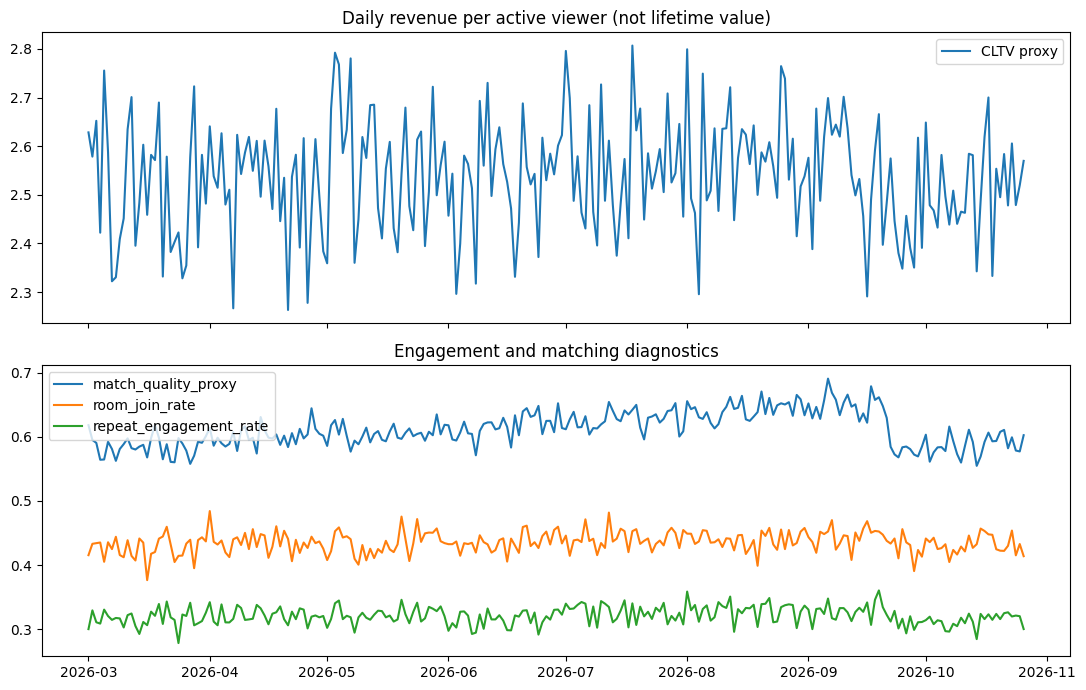

In [7]:
fig,axes=plt.subplots(2,1,figsize=(11,7),sharex=True)
axes[0].plot(df.day,df.cltv_proxy,label="CLTV proxy")
axes[0].set_title("Daily revenue per active viewer (not lifetime value)")
axes[0].legend()
for c in ["match_quality_proxy","room_join_rate","repeat_engagement_rate"]:
    axes[1].plot(df.day,df[c],label=c)
axes[1].legend();axes[1].set_title("Engagement and matching diagnostics")
plt.tight_layout();plt.show()

## Interpretation and production roadmap
- **Observe:** 1/7/30-day shifts, cohort mix, revenue per active viewer, conversion, and payer spend.
- **Explain accounting changes:** identify whether payer conversion or spend per payer moved; use appropriate weighting when aggregating periods.
- **Investigate hypotheses:** recommendation relevance → room joins → repeat engagement → payer conversion. These are *hypotheses*, not proven causal paths.
- **Validate:** time-aware holdouts, cohort controls, seasonality adjustments, experiments, and monitoring for instrumentation errors.
- **Avoid:** assuming follower counts or viewer–broadcaster pair counts capture relationship quality; use repeated engagement, meaningful sessions, and cohort-level retention instead.
- **Guard against leakage:** never feed realized future engagement as a known-future covariate.

**Privacy:** use aggregated or properly de-identified data and comply with internal data handling policies.